### Project Overview

This project presents an end-to-end Exploratory Data Analysis (EDA) on 119,390 hotel reservation records from two distinct hospitality properties in Portugal (a Resort Hotel in Algarve and a City Hotel in Lisbon). The study evaluates guest geographic origins, pricing dynamics (Average Daily Rate / ADR), seasonal rate fluctuations, guest length-of-stay behaviors, and revenue performance across distribution segments to guide data-driven revenue management and commercial strategy.

* **Environment & Tools**: Python, Pandas, NumPy, Matplotlib, Seaborn, Plotly (Express & Graph Objects), sort-dataframeby-monthorweek.

* **Dataset Scope**: 119,390 raw transactions spanning July 1, 2015 to August 31, 2017 across 32 attributes, including booking status (is_canceled), lead time, arrival schedules, room configurations, distribution channels, customer types, ADR, and special requests.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

data = pd.read_csv("/content/drive/MyDrive/Databaru/hotel_bookings.csv")
print(data)

               hotel  is_canceled  lead_time  arrival_date_year  \
0       Resort Hotel            0        342               2015   
1       Resort Hotel            0        737               2015   
2       Resort Hotel            0          7               2015   
3       Resort Hotel            0         13               2015   
4       Resort Hotel            0         14               2015   
...              ...          ...        ...                ...   
119385    City Hotel            0         23               2017   
119386    City Hotel            0        102               2017   
119387    City Hotel            0         34               2017   
119388    City Hotel            0        109               2017   
119389    City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
0                    July                        27   
1                    July                        27   
2                    July     

In [4]:
data.fillna(0, inplace=True)

filter = (data["children"] == 0) & (data["adults"] == 0 ) & (data["babies"] == 0)
index = data[filter].index
data.drop(index, inplace=True)

resort = data[(data["hotel"] == "Resort Hotel") & (data["is_canceled"] == 0)]
city = data[(data["hotel"] == "City Hotel") & (data["is_canceled"] == 0)]

### Data Cleaning & Preprocessing

* **Missing Value Imputation**: Initial inspection via data.isnull().sum() identified missing entries across country (488), agent (16,340), and company (112,593). Missing values in agent and company identifiers indicate direct, self-made guest reservations and were imputed with 0 via data.fillna(0, inplace=True).

* **Anomaly Filtering (Zero-Guest Bookings)**: An audit for invalid booking rows where adults, children, and babies simultaneously equaled zero uncovered 180 invalid entries. Dropping these anomalous rows refined the working dataset to 119,210 verified transactions.

* **Subsetting Valid Transactions**: Analyses focused on guest demographics, pricing, and length of stay were partitioned using is_canceled == 0 to exclude canceled reservations and prevent distorted revenue calculations.

In [5]:
!pip install plotly

In [6]:
label = resort["country"].value_counts().index
value = resort["country"].value_counts()

filter = value[value > 500]
index_filter = filter.index

print(filter)

country
PRT    10184
GBR     5922
ESP     3105
IRL     1734
FRA     1399
DEU     1057
CN       614
Name: count, dtype: int64


In [7]:
import plotly.graph_objects as go

trace = go.Pie(labels = index_filter,
               values = filter,
               hoverinfo="label+percent",
               textinfo="value")

fig = go.Figure(data = [trace])
fig.update_layout(width = 400, height = 400)
fig.show()


In [8]:
country_data = data[data["is_canceled"] == 0]["country"].value_counts().reset_index()
country_data

,country,count
0,PRT,20977
1,GBR,9668
2,FRA,8468
3,ESP,6383
4,DEU,6067
...,...,...
161,KIR,1
162,ATF,1
163,TJK,1
164,SLE,1


In [9]:
country_data.columns = ["country", "no of guest"]
country_data

,country,no of guest
0,PRT,20977
1,GBR,9668
2,FRA,8468
3,ESP,6383
4,DEU,6067
...,...,...
161,KIR,1
162,ATF,1
163,TJK,1
164,SLE,1


In [10]:
import plotly.express as px
map_guest = px.choropleth(country_data,
                          locations=country_data["country"],
                          color = country_data["no of guest"],
                          hover_name = country_data["country"],
                          title = "Country guest")

map_guest.show()

### Exploratory Data Analysis & Key Insights

A. Guest Origin & Geospatial Distribution

Evaluating guest distribution across home countries identified the primary geographic drivers of booking volume:

* **Portugal (PRT)**: Represents the dominant domestic market with 20,977 completed bookings across both properties (including 10,184 resort bookings).

* **Top International European Feeder Markets**: Great Britain (GBR) led overseas demand with 9,668 bookings, followed by France (FRA: 8,468), Spain (ESP: 6,383), and Germany (DEU: 6,067).

* **Long-Tail Global Reach**: Beyond Western and Southern Europe, reservations spanned 160+ origins across the Americas, Asia, and Africa, though individual country volumes remained low.

* **Behavioral Pattern**: The customer base is heavily anchored in domestic staycations and core European leisure travelers, making overall hotel occupancy highly sensitive to European travel and holiday calendars.

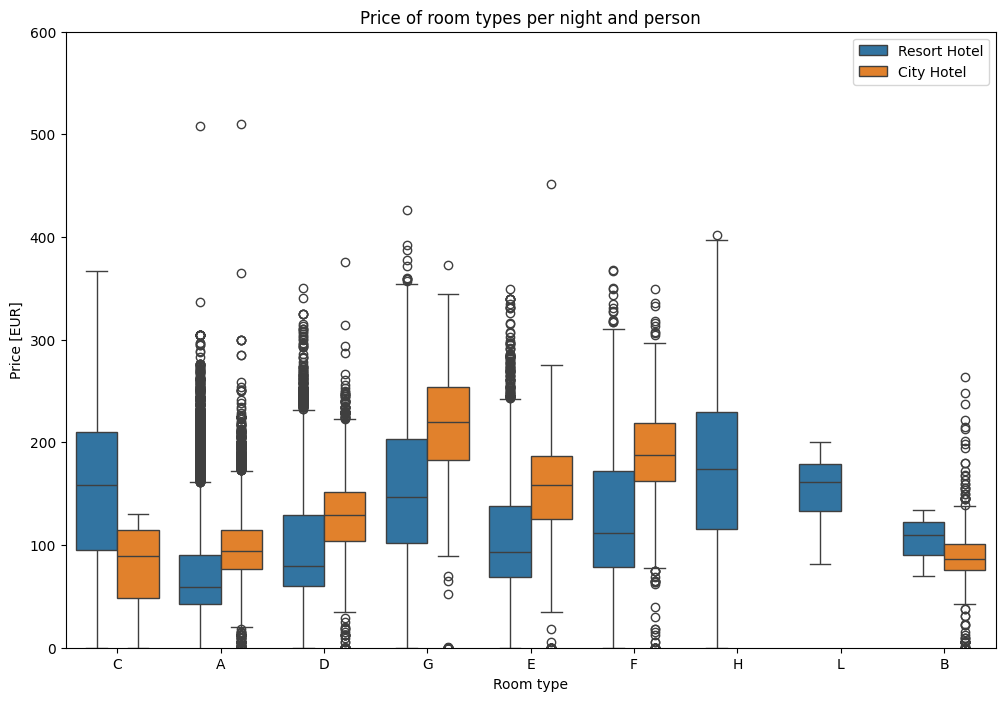

In [11]:
import seaborn as sns

data2 = data[data["is_canceled"] == 0]

plt.figure(figsize = (12, 8))
sns.boxplot(x = "reserved_room_type", y = "adr", hue = "hotel", data = data2)
plt.title("Price of room types per night and person")
plt.xlabel("Room type")
plt.ylabel("Price [EUR]")
plt.ylim(0, 600)
plt.legend(loc = "upper right")
plt.show()

B. Room Price Distribution Across Room Types (ADR)

Examining room rates across designated room classifications revealed significant price dispersion between property types:

* **Room Type A**: Operates as the baseline and highest-volume category, displaying extreme upper outliers reaching up to 500 EUR per night.

* **Room Type G**: Commands the highest median ADR in City Hotel (~220 EUR), significantly exceeding its resort counterpart.

* **Resort vs. City Hotel Variance**: Resort Hotel displays broader interquartile spreads across premium room categories (C, G, H), whereas City Hotel exhibits tighter clustering with higher median price floors across standard suites.

In [12]:
data_resort  = resort[resort["is_canceled"] == 0]
data_city = city[city["is_canceled"] == 0]

resort_hotel = data_resort.groupby(["arrival_date_month"])["adr"].mean().reset_index()
city_hotel = data_city.groupby(["arrival_date_month"])["adr"].mean().reset_index()

print(resort_hotel)
print(city_hotel)

   arrival_date_month         adr
0               April   75.867816
1              August  181.205892
2            December   68.410104
3            February   54.147478
4             January   48.761125
5                July  150.122528
6                June  107.974850
7               March   57.056838
8                 May   76.657558
9            November   48.706289
10            October   61.775449
11          September   96.416860
   arrival_date_month         adr
0               April  111.962267
1              August  118.674598
2            December   88.401855
3            February   86.520062
4             January   82.330983
5                July  115.818019
6                June  117.874360
7               March   90.658533
8                 May  120.669827
9            November   86.946592
10            October  102.004672
11          September  112.776582


In [13]:
final = resort_hotel.merge(city_hotel, on = "arrival_date_month")
print(final)

   arrival_date_month       adr_x       adr_y
0               April   75.867816  111.962267
1              August  181.205892  118.674598
2            December   68.410104   88.401855
3            February   54.147478   86.520062
4             January   48.761125   82.330983
5                July  150.122528  115.818019
6                June  107.974850  117.874360
7               March   57.056838   90.658533
8                 May   76.657558  120.669827
9            November   48.706289   86.946592
10            October   61.775449  102.004672
11          September   96.416860  112.776582


In [14]:
final.columns = ["month", "price_for_resort", "price_for_city_hotel"]
print(final)

        month  price_for_resort  price_for_city_hotel
0       April         75.867816            111.962267
1      August        181.205892            118.674598
2    December         68.410104             88.401855
3    February         54.147478             86.520062
4     January         48.761125             82.330983
5        July        150.122528            115.818019
6        June        107.974850            117.874360
7       March         57.056838             90.658533
8         May         76.657558            120.669827
9    November         48.706289             86.946592
10    October         61.775449            102.004672
11  September         96.416860            112.776582


In [15]:
!pip install sort-dataframeby-monthorweek
!pip install sorted-months-weekdays

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for sort-dataframeby-monthorweek: filename=sort_dataframeby_monthorweek-0.4-py3-none-any.whl size=3463 sha256=c0b68338fc0c9db698c59de1597104d3e171f54e5b4485cdf9c864df327ee4a1
  Stored in directory: /root/.cache/pip/wheels/1c/c5/0c/0e58cc328c70210dba56a2a91739745b71faaa3c0821671018
Successfully built sort-dataframeby-monthorweek
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for sorted-months-weekdays: filename=sorted_months_weekdays-0.2-py3-none-any.whl size=3268 sha256=db5242c9f079c7184d80c5a3473d51867a9b7b7b064181af7d15624fb500f698
  Stored in directory: /root/.cache/pip/wheels/1c/97/ef/b120c2d44bd865c740bd3e4d953061426dfbee28c7417c7671
Successfully built sorted-months-weekdays


In [16]:
import sort_dataframeby_monthorweek as sd

final2 = sd.Sort_Dataframeby_Month(final, "month")
final2

,month,price_for_resort,price_for_city_hotel
0,January,48.761125,82.330983
1,February,54.147478,86.520062
2,March,57.056838,90.658533
3,April,75.867816,111.962267
4,May,76.657558,120.669827
5,June,107.974850,117.874360
6,July,150.122528,115.818019
7,August,181.205892,118.674598
8,September,96.416860,112.776582
9,October,61.775449,102.004672


In [17]:
import plotly.express as px

fig = px.line(final2, x = "month", y = ["price_for_resort", "price_for_city_hotel"],
              title = "Room price per night over the Months")
fig.show()


C. Room Price Seasonality & Monthly Variations

Chronological aggregation of monthly Average Daily Rate (ADR) highlighted divergent pricing behaviors between the resort and metropolitan settings:

* **Resort Hotel (High Volatility)**: Highly cyclical summer surge peaking in August (181.21 EUR) and July (150.12 EUR), followed by sharp off-season contractions in November (48.71 EUR) and January (48.76 EUR).

* **City Hotel (Year-Round Stability)**: Maintains consistent rate stability throughout the year, peaking mildly during late spring and late summer (May at 120.67 EUR and August at 118.67 EUR), with troughs bottoming out at 82.33 EUR in January.

* **Strategic Implication**: Resort operations rely heavily on peak summer yield maximization to offset severe low-season revenue drops, whereas the City Hotel benefits from steady commercial and urban demand.

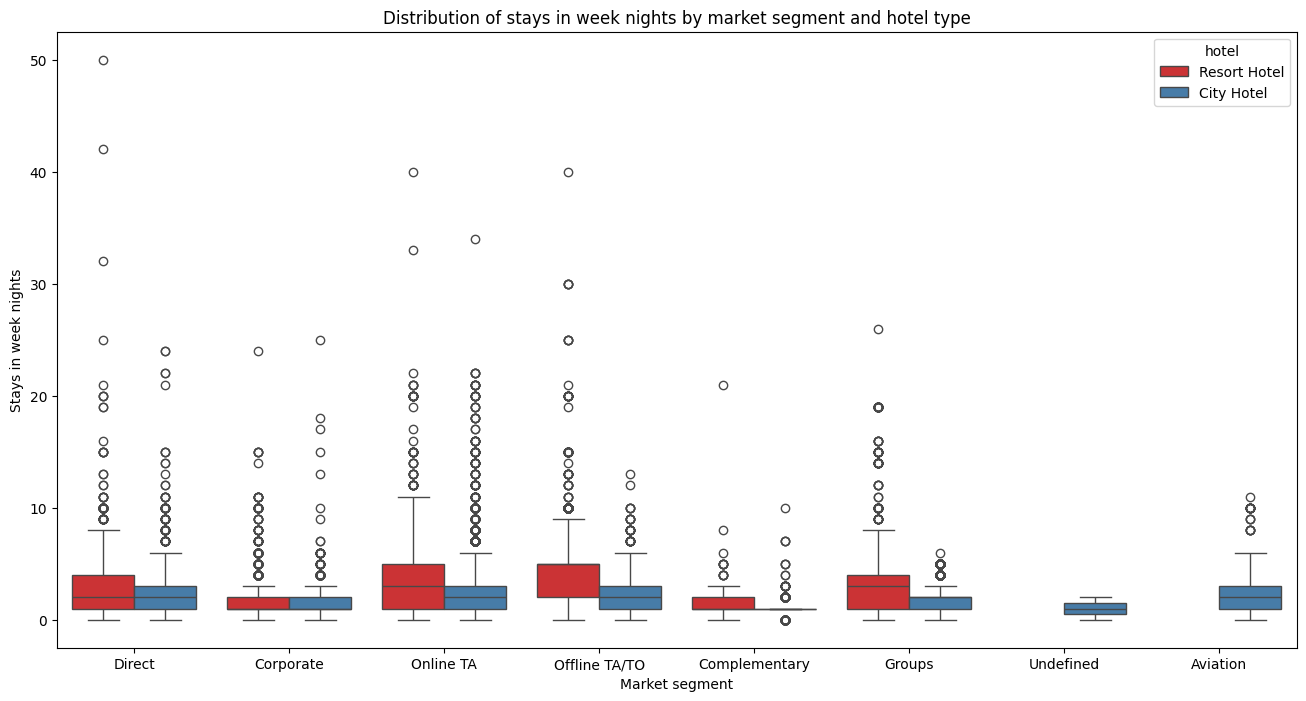

In [18]:
plt.figure(figsize = (16, 8))
sns.boxplot(x="market_segment", y="stays_in_week_nights", data=data, hue="hotel", palette="Set1")
plt.title("Distribution of stays in week nights by market segment and hotel type")
plt.xlabel("Market segment")
plt.ylabel("Stays in week nights")
plt.show()

D. Length of Stay Patterns Across Market Segments

Analyzing weeknight stays (stays_in_week_nights) categorized by market segment and hotel property revealed:

* **Short-Stay Concentration**: Across both properties, the vast majority of guests stay fewer than 5 weeknights (predominantly 1–3 nights).

* **Extended Resort Stays**: Guests booking Resort Hotel through Online TA, Offline TA/TO, and Direct channels regularly log extended durations of 10 to 14 nights.

* **Corporate & Groups**: Corporate reservations maintain tightly compressed durations of 1–2 nights with negligible variance, consistent with brief business trips.

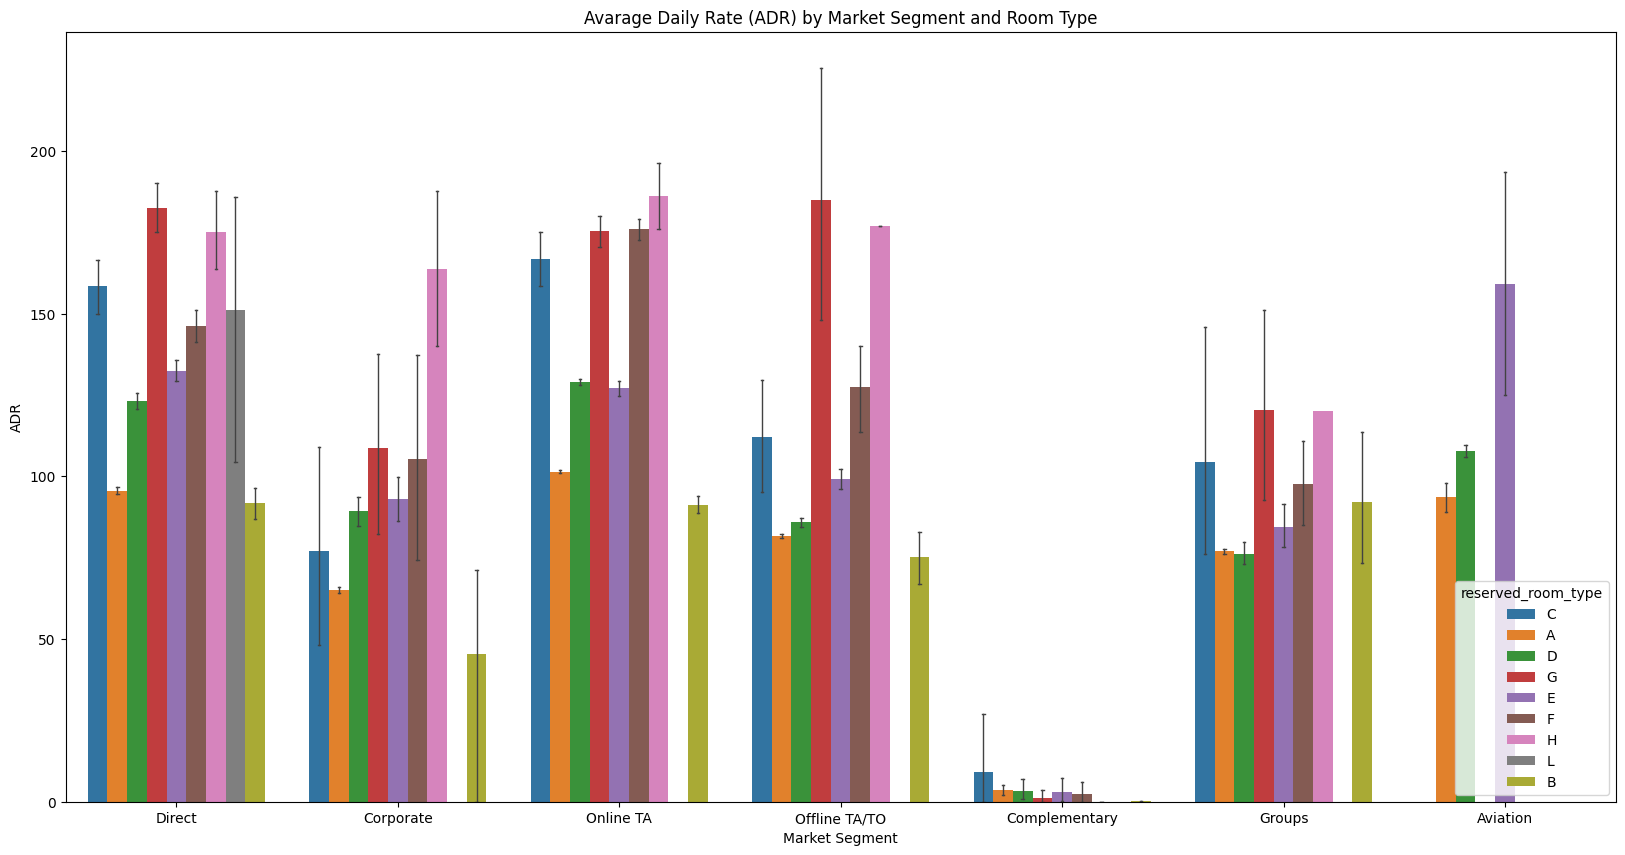

In [19]:
clean_data = data[data["is_canceled"] == 0]

plt.figure(figsize = (20, 10))
sns.barplot(x = "market_segment", y = "adr", hue = "reserved_room_type", data = clean_data,
            errwidth = 1, capsize = 0.1)
plt.title("Avarage Daily Rate (ADR) by Market Segment and Room Type")
plt.xlabel("Market Segment")
plt.ylabel("ADR")
plt.show()

E. Average Daily Rate (ADR) Yield by Room Type & Market Segment

Evaluating rate yield across distribution channels and room types demonstrated that sales channel mix directly dictates pricing leverage:

* **Online TA & Direct Channels:** Drive the highest average ADRs and comfortably absorb premium room rates (notably room types G, F, and C).
* **Corporate & Groups:** Exhibit discounted, homogeneous pricing structures with narrow error bars, reflecting negotiated corporate rates and bulk tour agreements.
* **Offline TA/TO:** Generates steady volume with balanced price distribution across standard family and couple suites.

### Strategic Business Recommendations

* **Dynamic Seasonal Yield Management:**
  * *Resort Hotel:* Capitalize on peak summer demand (June–August) through aggressive rate stepping and minimum-length-of-stay (MLOS) restrictions. During off-peak months (November–February), launch discounted wellness retreats, remote-work packages, and regional weekend getaways to maintain baseline occupancy.
  * *City Hotel:* Leverage year-round stability by dynamically raising corporate and transient rates during May and August MICE (Meetings, Incentives, Conferences, Exhibitions) surges.

* **Targeted Regional Marketing Campaigns:** Focus promotional ad spending and direct-booking incentives heavily on Great Britain, France, Spain, and Germany 60–90 days ahead of the summer holiday cycle.

* **Direct Booking Loyalty Perks:** Encourage direct reservations by bundling complimentary room upgrades for high-ADR categories (Types G and F) to reduce third-party OTA commission expenses.

* **Long-Stay Package Structuring:** Develop tiered multi-week discount packages tailored for resort vacationers staying 7+ nights to secure high-margin extended bookings ahead of shoulder seasons.